## Load data set

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
ORDER = ["Eastern", "North Central", "Northwest", "Olympic", "South Central", "Southwest"]
COLORS = dict(zip(ORDER, sns.color_palette("tab10", n_colors=6)))
candidates = [Path("housing_final.csv"), Path("data/housing_final.csv"), Path("../data/housing_final.csv")]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Place housing_final.csv beside the notebook, in data/, or in ../data/.")
housing = pd.read_csv(DATA_PATH, dtype={"county_fips": "string"})
df = housing[["county_fips", "county", "wsdot_region", "year", "unemployment_rate"]].copy()
df["county_fips"] = df["county_fips"].str.strip().str.zfill(5)
df["year"] = pd.to_numeric(df["year"], errors="raise").astype(int)
df["unemployment_rate"] = pd.to_numeric(df["unemployment_rate"], errors="raise")
START_YEAR, END_YEAR = 2015, 2024
YEARS = list(range(START_YEAR, END_YEAR + 1))
assert set(df["year"]) == set(YEARS), "Unexpected year coverage"
assert not df.isna().any().any(), "Missing values in EDA fields"
assert not df.duplicated(["county_fips", "year"]).any(), "Duplicate county-years"
assert df["county_fips"].str.fullmatch(r"53[0-9]{3}").all(), "Invalid WA FIPS"
assert set(df["wsdot_region"]) == set(ORDER), "Unexpected regions"
assert df.groupby("county_fips")["county"].nunique().eq(1).all()
assert df.groupby("county_fips")["wsdot_region"].nunique().eq(1).all()
assert df.groupby("county")["county_fips"].nunique().eq(1).all()
assert df["county_fips"].nunique() == 39
assert df.groupby("county_fips")["year"].agg(set).apply(lambda x: x == set(YEARS)).all()
assert df["unemployment_rate"].between(0, 100).all()
wide = df.pivot(index="county", columns="year", values="unemployment_rate")
region_of = df.drop_duplicates("county").set_index("county")["wsdot_region"]
county_map = df[["county_fips", "county", "wsdot_region"]].drop_duplicates().sort_values(["wsdot_region", "county"])
print("Source:", DATA_PATH)
print(f"Validated {len(df)} observations: 39 counties × {len(YEARS)} years.")

Source: housing_final.csv
Validated 390 observations: 39 counties × 10 years.


## Overview and data quality

In [4]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate county-years:", int(df.duplicated(["county_fips", "year"]).sum()))
print("\nCounties per WSDOT region:")
print(county_map["wsdot_region"].value_counts().reindex(ORDER).to_string())
county_map.reset_index(drop=True)

Missing values: 0
Duplicate county-years: 0

Counties per WSDOT region:
wsdot_region
Eastern          7
North Central    4
Northwest        6
Olympic          7
South Central    8
Southwest        7


,county_fips,county,wsdot_region
0,53001,Adams County,Eastern
1,53019,Ferry County,Eastern
2,53043,Lincoln County,Eastern
3,53051,Pend Oreille County,Eastern
4,53063,Spokane County,Eastern
5,53065,Stevens County,Eastern
6,53075,Whitman County,Eastern
7,53007,Chelan County,North Central
8,53017,Douglas County,North Central
9,53025,Grant County,North Central


The full panel has 390 observations and 39 counties. Each county has all ten years and one stable WSDOT region. Classification is taken from the supplied housing file rather than reconstructed from county names. These checks establish alignment with that file, not an independent audit of its classification against WSDOT documentation.

## Distribution of unemployment rates

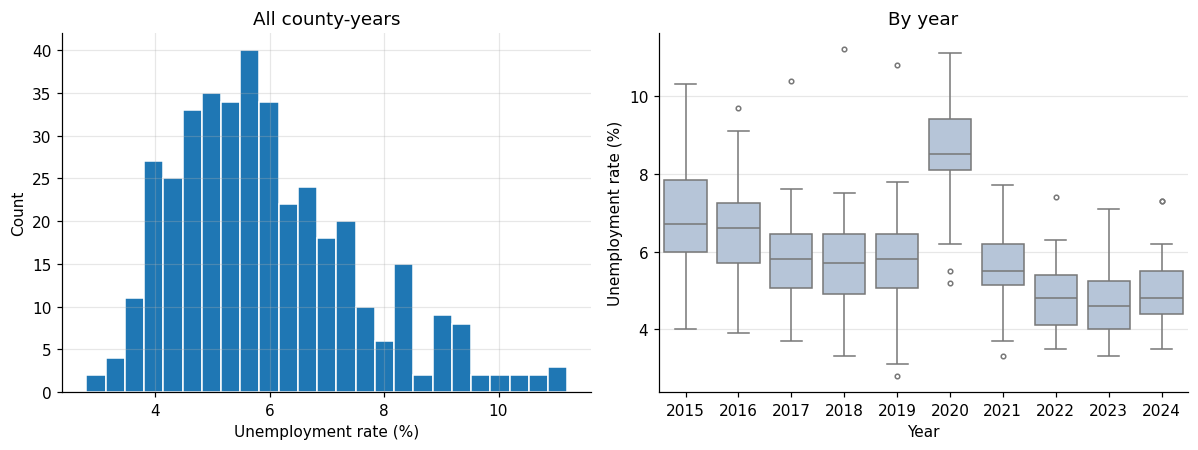

Skewness: 0.84


,mean,median,min,max,std
year,,,,,
2015,6.93,6.7,4.0,10.3,1.49
2016,6.56,6.6,3.9,9.7,1.31
2017,5.83,5.8,3.7,10.4,1.25
2018,5.76,5.7,3.3,11.2,1.33
2019,5.82,5.8,2.8,10.8,1.45
2020,8.60,8.5,5.2,11.1,1.29
2021,5.65,5.5,3.3,7.7,0.94
2022,4.80,4.8,3.5,7.4,0.88
2023,4.70,4.6,3.3,7.1,0.87


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].hist(df["unemployment_rate"], bins=25, edgecolor="white")
axes[0].set(title="All county-years", xlabel="Unemployment rate (%)", ylabel="Count")
sns.boxplot(data=df, x="year", y="unemployment_rate", ax=axes[1], color="lightsteelblue", fliersize=3)
axes[1].set(title="By year", xlabel="Year", ylabel="Unemployment rate (%)")
plt.tight_layout(); plt.show()
print("Skewness:", round(df["unemployment_rate"].skew(), 2))
df.groupby("year")["unemployment_rate"].agg(["mean", "median", "min", "max", "std"]).round(2)

Unemployment rates are slightly right-skewed, with most county-year observations between 4% and 7% and a few above 10%. The yearly boxplots show declining rates before 2020, a sharp increase during the pandemic, and a subsequent recovery. Differences across counties remain, although the spread is narrower in recent years.

## Mean across all Washington counties

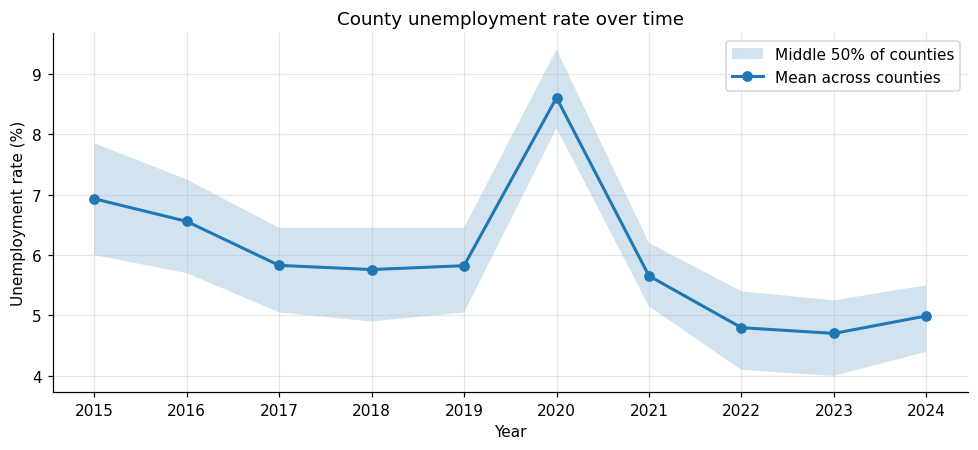

In [9]:
yr = df.groupby("year")["unemployment_rate"]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.fill_between(yr.mean().index, yr.quantile(0.25), yr.quantile(0.75), alpha=0.2, label="Middle 50% of counties")
ax.plot(yr.mean().index, yr.mean(), marker="o", lw=2, label="Mean across counties")
ax.set(title="County unemployment rate over time", xlabel="Year", ylabel="Unemployment rate (%)"); ax.set_xticks(YEARS); ax.legend()
plt.tight_layout(); plt.show()

In [10]:
annual = df.groupby("year")["unemployment_rate"].agg(["mean", "std"])
print(f"Mean county rate: {annual.loc[2015, 'mean']:.2f}% in 2015; "
      f"{annual.loc[2019, 'mean']:.2f}% in 2019; {annual.loc[2020, 'mean']:.2f}% in 2020; "
      f"{annual.loc[2023, 'mean']:.2f}% in 2023; {annual.loc[2024, 'mean']:.2f}% in 2024.")
print(f"Across-county SD: {annual.loc[2015, 'std']:.2f} percentage points in 2015 "
      f"and {annual.loc[2024, 'std']:.2f} in 2024.")

Mean county rate: 6.93% in 2015; 5.82% in 2019; 8.60% in 2020; 4.70% in 2023; 4.99% in 2024.
Across-county SD: 1.49 percentage points in 2015 and 0.86 in 2024.


The average county rate fell from 6.9% (2015) to 5.8% in 2017-2019, spiked to 8.6% in 2020, then fell below pre-pandemic levels to 4.7% in 2023 (4.99% in 2024). The spread across counties also narrowed, from a standard deviation of 1.49 points in 2015 to about 0.86 in 2024.

## Trends by WSDOT region

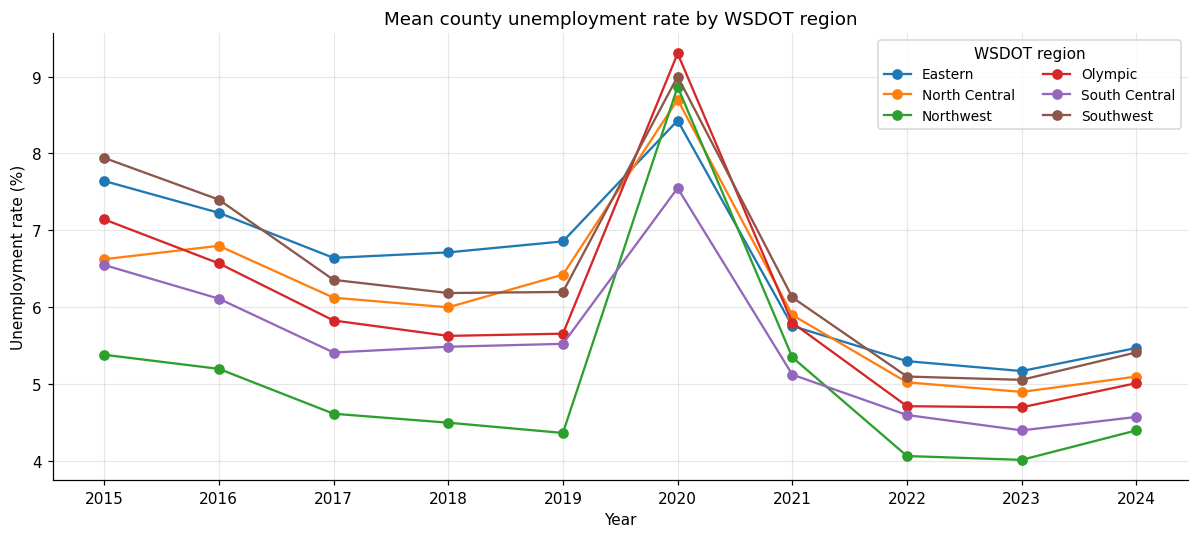

wsdot_region,Eastern,North Central,Northwest,Olympic,South Central,Southwest
year,,,,,,
2015,7.64,6.62,5.38,7.14,6.55,7.94
2016,7.23,6.80,5.20,6.57,6.11,7.40
2017,6.64,6.12,4.62,5.83,5.41,6.36
2018,6.71,6.00,4.50,5.63,5.49,6.19
2019,6.86,6.42,4.37,5.66,5.52,6.20
2020,8.43,8.70,8.87,9.30,7.55,9.00
2021,5.76,5.90,5.35,5.80,5.12,6.13
2022,5.30,5.03,4.07,4.71,4.60,5.10
2023,5.17,4.90,4.02,4.70,4.40,5.06


In [13]:
reg = df.pivot_table(index="year", columns="wsdot_region", values="unemployment_rate", aggfunc="mean").reindex(columns=ORDER)
fig, ax = plt.subplots(figsize=(11, 5))
for r in ORDER:
    ax.plot(reg.index, reg[r], marker="o", color=COLORS[r], label=r)
ax.set(title="Mean county unemployment rate by WSDOT region", xlabel="Year", ylabel="Unemployment rate (%)", xticks=YEARS)
ax.legend(title="WSDOT region", ncol=2, fontsize=9)
plt.tight_layout(); plt.show()
reg.round(2)

All six regions show a similar pattern: unemployment generally declined before 2020, rose sharply during the pandemic, and then fell. Regional differences narrowed after 2020, with rates remaining below their 2015 levels by 2024.

Northwest has the lowest mean county unemployment rate in every year from 2015–2019. In 2020, Olympic has the highest mean (9.30%) and South Central the lowest (7.55%). By 2024, Northwest is again lowest (4.40%), while Eastern is highest (5.47%).

In [15]:
regional_summary = pd.DataFrame({
    "counties": county_map.groupby("wsdot_region").size(),
    "mean_2015_2024": df.groupby("wsdot_region")["unemployment_rate"].mean(),
    "rate_2015": reg.loc[2015], "rate_2019": reg.loc[2019],
    "rate_2020": reg.loc[2020], "rate_2024": reg.loc[2024]
}).reindex(ORDER)
regional_summary["change_2015_2024_pp"] = regional_summary["rate_2024"] - regional_summary["rate_2015"]
regional_summary["change_2019_2020_pp"] = regional_summary["rate_2020"] - regional_summary["rate_2019"]
regional_summary.round(2)

,counties,mean_2015_2024,rate_2015,rate_2019,rate_2020,rate_2024,change_2015_2024_pp,change_2019_2020_pp
wsdot_region,,,,,,,,
Eastern,7,6.52,7.64,6.86,8.43,5.47,-2.17,1.57
North Central,4,6.16,6.62,6.42,8.70,5.10,-1.53,2.27
Northwest,6,5.08,5.38,4.37,8.87,4.40,-0.98,4.50
Olympic,7,6.04,7.14,5.66,9.30,5.01,-2.13,3.64
South Central,8,5.53,6.55,5.52,7.55,4.58,-1.97,2.02
Southwest,7,6.48,7.94,6.20,9.00,5.41,-2.53,2.80


Northwest had the lowest ten-year average (5.08%), while Eastern had the highest (6.52%). Southwest recorded the largest decline from 2015 to 2024 (2.53 percentage points), whereas Northwest experienced the largest increase from 2019 to 2020 (4.50 percentage points).

## County-level heatmap

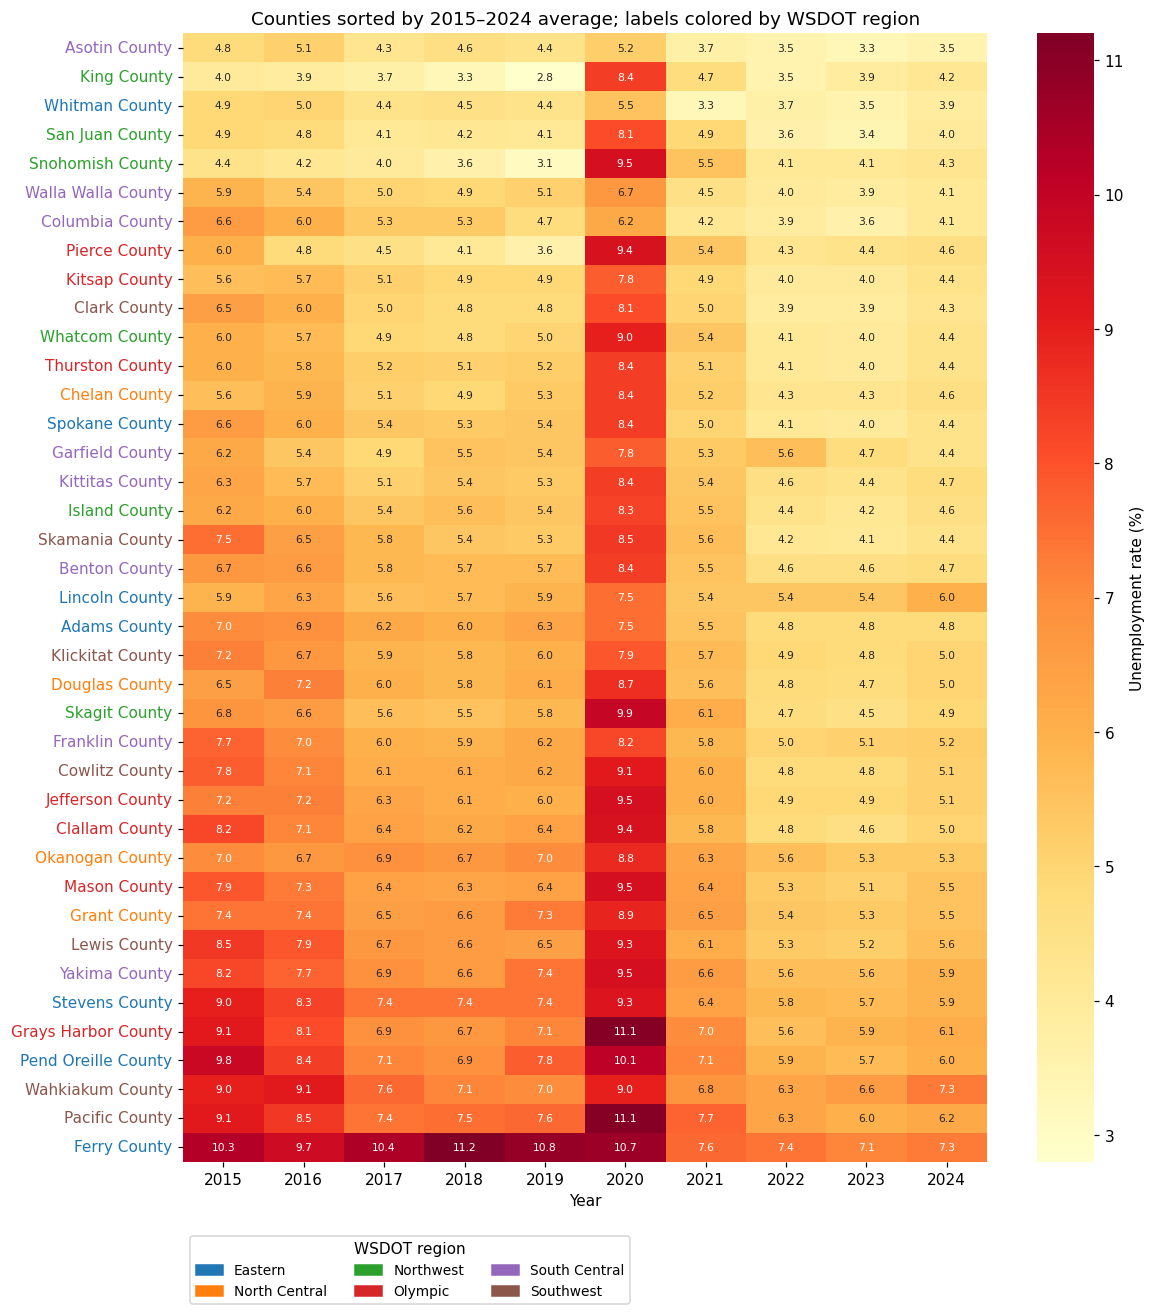

In [17]:
order = wide.mean(axis=1).sort_values().index
fig, ax = plt.subplots(figsize=(11, 12))
sns.heatmap(wide.loc[order], cmap="YlOrRd", annot=True, fmt=".1f", annot_kws={"size": 7},
            cbar_kws={"label": "Unemployment rate (%)"}, ax=ax)
for lbl in ax.get_yticklabels():
    lbl.set_color(COLORS[region_of[lbl.get_text()]])
ax.set(title="Counties sorted by 2015–2024 average; labels colored by WSDOT region", xlabel="Year", ylabel="")
ax.grid(False)
ax.legend(handles=[Patch(color=COLORS[r], label=r) for r in ORDER], loc="upper left",
          bbox_to_anchor=(0, -0.06), ncol=3, title="WSDOT region", fontsize=9)
plt.tight_layout(); plt.show()

The heatmap highlights persistent differences between counties. Ferry generally had high unemployment rates, while King, Asotin, and Whitman had relatively low rates. The darker colors in 2020 show the widespread pandemic-era increase. Counties within the same WSDOT region also vary considerably, showing that regional averages can mask local differences.

## Highest and lowest counties; change from 2015 to 2024

In [19]:
summary = pd.DataFrame({"wsdot_region": region_of, "mean_2015_2024": wide.mean(axis=1), "rate_2015": wide[2015], "rate_2019": wide[2019], "rate_2020": wide[2020], "rate_2024": wide[2024]})
summary["change_2015_2024"] = summary["rate_2024"] - summary["rate_2015"]
summary = summary.sort_values("mean_2015_2024")
print("Lowest 5 counties (10-year average):"); print(summary.head(5).round(2).to_string())
print("\nHighest 5 counties:"); print(summary.tail(5).round(2).to_string())
print("\nLargest declines 2015 -> 2024:"); print(summary.nsmallest(4, "change_2015_2024")[["wsdot_region", "rate_2015", "rate_2024", "change_2015_2024"]].round(2).to_string())
print("\nLargest increases / smallest declines:"); print(summary.nlargest(4, "change_2015_2024")[["wsdot_region", "rate_2015", "rate_2024", "change_2015_2024"]].round(2).to_string())

Lowest 5 counties (10-year average):
                   wsdot_region  mean_2015_2024  rate_2015  rate_2019  rate_2020  rate_2024  change_2015_2024
county                                                                                                       
Asotin County     South Central            4.24        4.8        4.4        5.2        3.5              -1.3
King County           Northwest            4.24        4.0        2.8        8.4        4.2               0.2
Whitman County          Eastern            4.31        4.9        4.4        5.5        3.9              -1.0
San Juan County       Northwest            4.61        4.9        4.1        8.1        4.0              -0.9
Snohomish County      Northwest            4.68        4.4        3.1        9.5        4.3              -0.1

Highest 5 counties:
                    wsdot_region  mean_2015_2024  rate_2015  rate_2019  rate_2020  rate_2024  change_2015_2024
county                                                       

Individual county averages are unchanged by relabeling. Their regional memberships and regional summaries do change. Asotin and King have the lowest ten-year means (both about 4.24%); Ferry has the highest (9.25%). Whitman's low mean and Ferry's high mean show considerable variation within Eastern.

## Compare all six regions

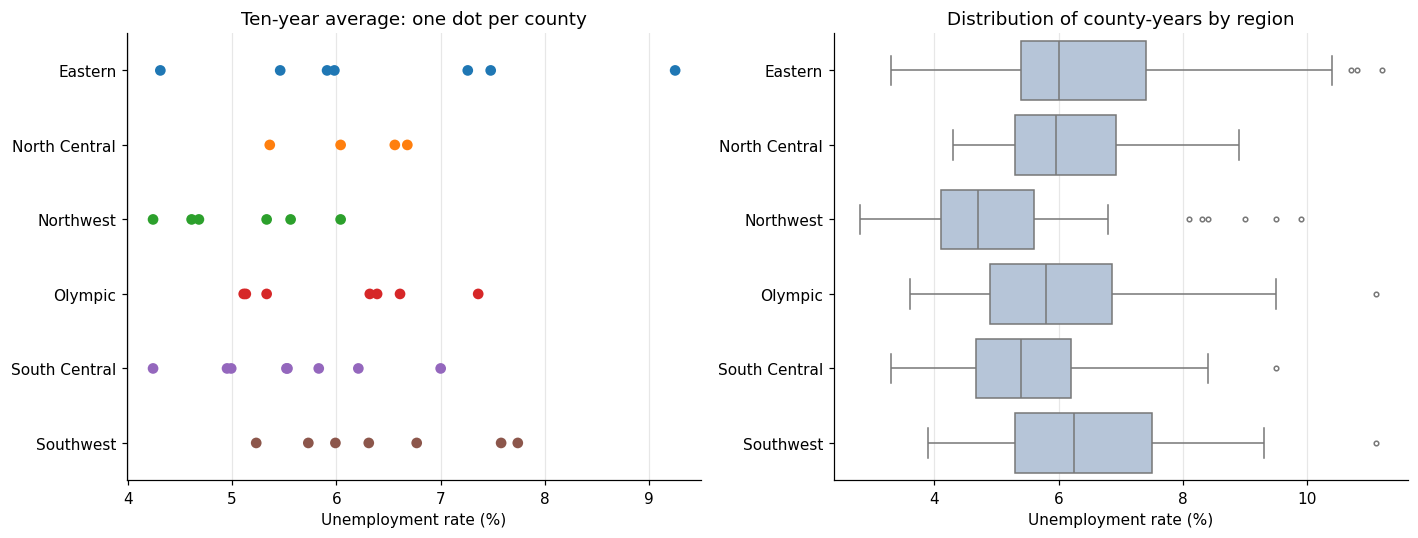

,count,mean,std,min,max
wsdot_region,,,,,
Eastern,7,6.52,1.61,4.31,9.25
North Central,4,6.16,0.60,5.36,6.68
Northwest,6,5.08,0.68,4.24,6.04
Olympic,7,6.04,0.86,5.11,7.36
South Central,8,5.53,0.85,4.24,7.00
Southwest,7,6.48,0.94,5.23,7.74


In [22]:
cm = df.groupby(["county_fips", "county", "wsdot_region"], as_index=False)["unemployment_rate"].mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.stripplot(data=cm, y="wsdot_region", x="unemployment_rate", order=ORDER,
              hue="wsdot_region", palette=COLORS, jitter=False, size=7, ax=axes[0])
if axes[0].get_legend() is not None: axes[0].get_legend().remove()
axes[0].set(title="Ten-year average: one dot per county", ylabel="", xlabel="Unemployment rate (%)")
sns.boxplot(data=df, y="wsdot_region", x="unemployment_rate", order=ORDER,
            color="lightsteelblue", fliersize=3, ax=axes[1])
axes[1].set(title="Distribution of county-years by region", ylabel="", xlabel="Unemployment rate (%)")
plt.tight_layout(); plt.show()
cm.groupby("wsdot_region")["unemployment_rate"].agg(["count", "mean", "std", "min", "max"]).reindex(ORDER).round(2)

The county averages show substantial overlap across regions, with particularly wide variation within Eastern. Northwest generally has lower unemployment, although some counties in other regions have similarly low rates. The county-year boxplots also show considerable overlap and several high observations, indicating that regional membership alone does not fully explain differences in unemployment.

## Differences between counties vs. changes over time

Share of total sum of squares attributable to county means: 43.3%
The remainder includes time changes and county-specific changes; it is not all a common year effect.
2015 vs 2019 correlation: 0.89
2015 vs 2024 correlation: 0.84


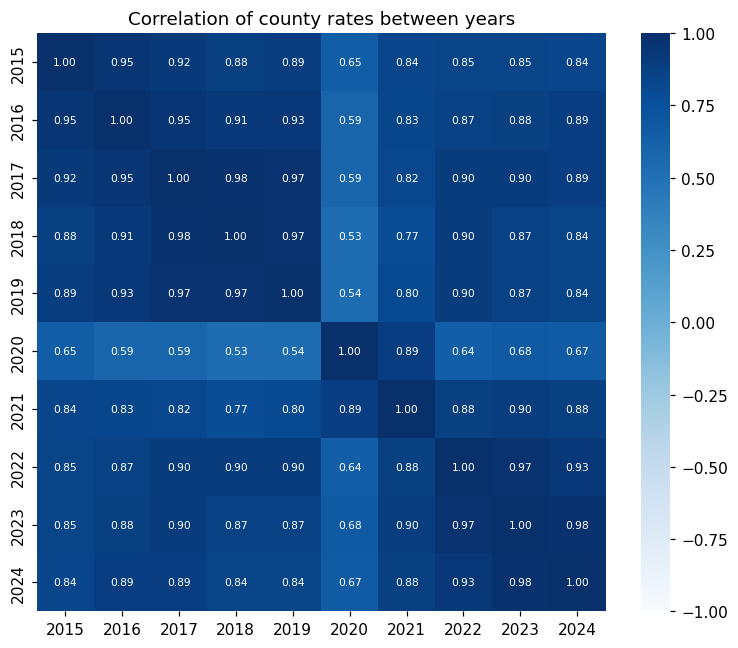

In [24]:
# Exact sum-of-squares decomposition, using all county-year observations.
grand_mean = df["unemployment_rate"].mean()
county_mean_per_row = df.groupby("county_fips")["unemployment_rate"].transform("mean")
ss_total = ((df["unemployment_rate"] - grand_mean) ** 2).sum()
ss_between = ((county_mean_per_row - grand_mean) ** 2).sum()
ss_within = ((df["unemployment_rate"] - county_mean_per_row) ** 2).sum()
assert np.isclose(ss_total, ss_between + ss_within)
print(f"Share of total sum of squares attributable to county means: {ss_between / ss_total:.1%}")
print("The remainder includes time changes and county-specific changes; it is not all a common year effect.")
print(f"2015 vs 2019 correlation: {wide[2015].corr(wide[2019]):.2f}")
print(f"2015 vs 2024 correlation: {wide[2015].corr(wide[2024]):.2f}")
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(wide.corr(), annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1, annot_kws={"size": 7}, ax=ax)
ax.grid(False)
ax.set(title="Correlation of county rates between years", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

Counties with relatively high unemployment in one year generally remained high in later years, as shown by the strong correlations between 2015 and 2019 (0.89) and between 2015 and 2024 (0.84). Correlations involving 2020 are weaker, suggesting that the pandemic disrupted county patterns unevenly. Overall, unemployment reflects both persistent differences between counties and changes over time.

## Outliers (IQR rule)

In [27]:
q1, q3 = df["unemployment_rate"].quantile([0.25, 0.75])
lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
print(f"Lower fence: {lower:.2f}% | Upper fence: {upper:.2f}%")
outliers = df.loc[~df["unemployment_rate"].between(lower, upper)].sort_values("unemployment_rate", ascending=False)
outliers[["county", "wsdot_region", "year", "unemployment_rate"]]

Lower fence: 1.65% | Upper fence: 10.05%


,county,wsdot_region,year,unemployment_rate
93,Ferry County,Eastern,2018,11.2
135,Grays Harbor County,Olympic,2020,11.1
245,Pacific County,Southwest,2020,11.1
94,Ferry County,Eastern,2019,10.8
95,Ferry County,Eastern,2020,10.7
92,Ferry County,Eastern,2017,10.4
90,Ferry County,Eastern,2015,10.3
255,Pend Oreille County,Eastern,2020,10.1


The IQR rule flags unemployment rates above 10.05%, including several observations from Ferry and the 2020 peaks in Grays Harbor, Pacific, and Pend Oreille. These values may reflect persistent local conditions or pandemic-related increases rather than data errors, so they should be retained unless source verification indicates otherwise.